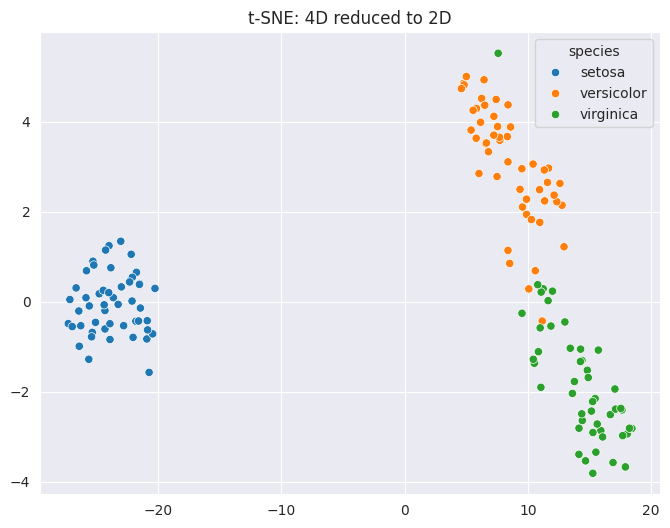

In [28]:
##### Unsupervised Learning and Recommendations with Scikit Learn #####
# The following topics are covered in this tutorial:
#  1. Overview of unsupervised learning algorithms in Scikit-learn
#  2. Clustering algorithms: K Means, DBScan, Hierarchical clustering etc.
#  3. Dimensionality reduction (PCA) and manifold learning (t-SNE)

# Welcome to the other side of Machine Learning: Unsupervised Learning.
# Everything you've done up to this point (Linear Regression, Logistic Regression, Decision Trees, Random Forests, XGBoost) has been Supervised Learning.
# You always had an answer key (the targets column).
# Now, there is no answer key. You just give the model the data and say, "Find the patterns."

# Introduction to Unsupervised Learning
# Unsupervised machine learning refers to the category of machine learning techniques where models are trained on a dataset without labels.
# Unsupervised learning is generally use to discover patterns in data and reduce high-dimensional data to fewer dimensions.


### Clustering
# Clustering is the process of grouping objects from a dataset such that objects in the same group (called a cluster) are more similar to each other
# than to those in other groups.
# The Key Difference: Unlike the models you've built so far (Linear Regression, XGBoost), clustering is unsupervised.
# You don't give the model any labels or answers. You just give it data and ask it to find the natural groupings.

# Real-world Example:
# Imagine you are a bank manager with data on your customers' Income and Debt.
# Without clustering, you just have a massive list of numbers.
# With clustering, the algorithm finds natural groups:
#  -> Group A: High income, low debt.
#  -> Group B: Low income, high debt.
#  -> Group C: High income, high debt.
# You can now use these groups to make business decisions (e.g., send Group B financial counseling offers, and Group C premium credit card offers).

# Common Applications:
#  -> Customer segmentation
#  -> Product recommendation
#  -> Anomaly/fraud detection
#  -> Taxonomy creation (grouping similar items)

## We'll use the Iris flower dataset to study some of the clustering algorithms available in scikit-learn. It contains various measurements for 150 flowers
#  belonging to 3 different species.

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')
%matplotlib inline

# Load the famous Iris dataset from Seaborn
iris_df = sns.load_dataset('iris')

#iris_df

#sns.scatterplot(data=iris_df, x='sepal_length', y='petal_length', hue='species');

# sns.load_dataset('iris') downloads the Iris flower dataset. It contains 150 flowers from 3 different species (Setosa, Versicolor, Virginica).
# For each flower, it records 4 measurements: sepal length, sepal width, petal length, and petal width.
# The goal: We are going to feed the model ONLY the 4 measurements (with no species label) and see if K-Means can figure out the 3 species on its own.

## Note: sns.load_dataset('iris') fetches a built-in dataset directly from the Seaborn library's online repository.
#  It contains 150 rows and 5 columns (4 numeric features + the species label).

### We'll attempt to cluster observations using numeric columns in the data.
# Select only the numeric columns (ignore the species column)
numeric_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = iris_df[numeric_cols]

# Check the shape
#print("X shape:", X.shape)
#X

# We are creating X, which only contains the 4 measurements.
# We are not giving the model the species column. We are testing if it can figure out the species on its own based on the measurements.


### K Means Clustering
# The K-means algorithm attempts to classify objects into a pre-determined number of clusters by finding optimal central points (called centroids)
# for each cluster. Each object is classifed as belonging the cluster represented by the closest centroid.

# Here's how the K-means algorithm works:
#  1. Pick K random objects as the initial cluster centers.
#  2. Classify each object into the cluster whose center is closest to the point.
#  3. For each cluster of classified objects, compute the centroid (mean).
#  4. Now reclassify each object using the centroids as cluster centers.
#  5. Calculate the total variance of the clusters (this is the measure of goodness).
#  6. Repeat steps 1 to 6 a few more times and pick the cluster centers with the lowest total variance.

## The Analogy: The "Lost Hikers"
# Imagine you are dropping 3 team leaders (centroids) into a forest to gather lost hikers (data points).
#  1. Pick K random objects: You blindfold the 3 leaders and drop them randomly in the forest. (These are your initial random centers).
#  2. Classify each object: Every hiker looks around, finds the closest leader, and walks to them. Now you have 3 groups.
#  3. Compute the centroid (mean): Each leader looks at the group of hikers they gathered, finds the exact geographic center of that group, and moves there.
#  4. Reclassify: Because the leaders moved, the hikers look around again. Some hikers might realize, "Wait, Leader B is now closer to me than Leader A,"
#     and they switch groups.
#  5. Calculate variance (Inertia): We measure how tightly packed the groups are. If hikers are spread far away from their leader, the variance is high (bad).
#     If they are hugging the leader, the variance is low (good).
#  6. Repeat: The leaders move again, hikers switch, and we measure the variance. We keep doing this until the leaders stop moving.

# The Final Result
# The algorithm runs this whole process multiple times (because the initial drop point was random).
# It picks the final grouping that resulted in the lowest total variance (the tightest clusters).

## Note: K-Means finds K centroids (centers) and assigns each data point to the nearest centroid. It iteratively updates the centroids to be the mean of the
#  points in their cluster, repeating until the clusters stop changing and the variance (inertia) is minimized.

## Let's apply K-means clustering to the Iris dataset.
from sklearn.cluster import KMeans

# Create the model with 3 clusters
model = KMeans(n_clusters=3, random_state=42)

# Fit the model to the data
model.fit(X)

#print("Model trained!")

# n_clusters=3: We are telling the algorithm to find exactly 3 groups. (We know there are 3 species of Iris, so 3 is a good guess).
# random_state=42: Just like before, this ensures the random starting points are the same every time you run the code.
# model.fit(X): This is where the magic happens. The algorithm will place 3 random dots (centroids), group the flowers around them,
# recalculate the center, and repeat until it finds the best 3 groups.


## Here is the "Lost Hikers" analogy applied directly to your Iris data table:
#   1. Pick 3 Random Flowers (The Initial Centers)
#     The computer randomly picks 3 flowers from your table (let's say Row 0, Row 50, and Row 100). It says: *"You three are the leaders (centroids)."*
#    - **Leader A:** 5.1, 3.5, 1.4, 0.2
#    - **Leader B:** (some random flower)
#    - **Leader C:** 6.7, 3.0, 5.2, 2.3

#   2. Grouping (Distance)
#    Now, every other flower looks at the 4 numbers for Leader A, B, and C.
#    Flower 1 is `4.9, 3.0, 1.4, 0.2`.
#    It does the math: *"I am very close to Leader A (1.4 and 0.2 match). I am very far from Leader C (5.2 and 2.3)."*
#    So, Flower 1 walks to Leader A.

#    Flower 145 is `6.7, 3.0, 5.2, 2.3`.
#    It does the math: *"I am very close to Leader C. I will walk to Leader C."*

#   3. The Mean (Centroid)
#   Leader A looks at all the flowers that walked to them. They are all small flowers (petal length ~1.4, petal width ~0.2).
#   The average (mean) of their measurements is exactly `1.4` and `0.2`. So, Leader A stays right there.

#    Leader C looks at their group. They are all big flowers (petal length ~5.0, width ~2.0). The average of this group is exactly that.
#    So, Leader C moves to that exact average spot.

#   4. Reclassify
#   Because Leader C moved to the average spot, maybe one flower that was on the border between B and C realizes:
#   *"Wait, now Leader C is closer to me!"* and switches.

#   5. Inertia (The Goodness)
#   We measure the distance from every flower to its Leader.
#  - Because we grouped flowers that have similar petal lengths (all the 1.4s together, all the 5.2s together), the distance is tiny.
#    The total variance (inertia) is low.

#  6. Repeat
#  The leaders move again. Then the flowers switch again. The computer keeps doing this until the leaders don't move at all.


##  **The Final Result:**
#  The computer will look at the 150 rows and say, *"I have no idea what 'Setosa' or 'Virginica' means. But based on the numbers,
#  Cluster A is all the flowers with petal width 0.2, Cluster B is all the 1.4s, and Cluster C is all the 2.3s."*

# **Note:** K-Means groups the rows based on the distance between their numbers. It doesn't know the species; it just notices that rows 0-4 are
#  mathematically similar (small petals) and rows 145-149 are mathematically similar (large petals).


## We can check the cluster centers for each cluster.
#model.cluster_centers_

# array([[6.85384615, 3.07692308, 5.71538462, 2.05384615],
#       [5.006     , 3.428     , 1.462     , 0.246     ],
#       [5.88360656, 2.74098361, 4.38852459, 1.43442623]])

# cluster_centers_: This prints the final coordinates (the averages) of the 3 centroids.

# What do these numbers mean?
# Each row is one of the 3 centroids (the "leaders"). Each column is a feature (sepal_length, sepal_width, petal_length, petal_width).
# For example, the second row (5.006, 3.428, 1.462, 0.246) means that one of the clusters has an average petal length of 1.46 and
# an average petal width of 0.24.
# We know from the data that the "Setosa" flowers have these exact measurements. So, the model has discovered the Setosa cluster entirely on its own!


## Make Predictions (Assign clusters)
# We can now classify points using the model.
# Predict the cluster for all 150 flowers
preds = model.predict(X)

#print(preds)

# -> preds will be an array of 150 numbers (0, 1, or 2).
# -> It tells you: "Flower 0 is in Cluster 1. Flower 50 is in Cluster 0."

## Visualize the Clusters
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Plot the flowers, colored by the PREDICTED clusters
#sns.scatterplot(data=X, x='sepal_length', y='petal_length', hue=preds)

# 2. Plot the centroids as black X's
#centers_x, centers_y = model.cluster_centers_[:, 0], model.cluster_centers_[:, 2]
#plt.plot(centers_x, centers_y, 'xb', markersize=12, markeredgewidth=3)

#plt.title('K-Means Clusters')
#plt.show()

# -> The dots are colored by preds (the clusters the model guessed, 0, 1, or 2).
# -> The X marks are the cluster_centers_ (the leaders).
# -> cluster_centers_[:, 0] extracts the sepal_length (X-axis) and [:, 2] extracts the petal_length (Y-axis) for the centroids,
#    so they line up with the scatter plot.

## As you can see, K-means algorithm was able to classify (for the most part) different specifies of flowers into separate clusters.
#  Note that we did not provide the "species" column as an input to `KMeans`.

###  Check the "Goodness" (Inertia)
# How do we know if the clusters are tight? We check the inertia_. Lower inertia means the flowers are hugging the centroid tightly.
#print("Inertia:", model.inertia_)

# Note: inertia_ is the sum of squared distances from each point to its cluster center. It measures how tight the clusters are.
# A lower inertia means the clusters are more compact.

# Inertia is a relative metric. It doesn't have a universal "good" or "bad" scale like a percentage. You have to compare it to other models.
# Here is how you actually evaluate it in the real world:
#  1.Compare Inertia Across Different K values (The Elbow Method)
#     If you run K-Means with n_clusters=2 and get an inertia of 500, and then run it with n_clusters=3 and get 78, you know 3 is much better than 2 because
#     the inertia dropped drastically.
#     But if you run n_clusters=4 and the inertia is 75, adding that 4th cluster only improved the score by 3 points.
#     That means 3 was the "sweet spot" (the elbow).
#  2.Compare Inertia to the Data Scale
#     Inertia is in squared units of your data.
#     The Iris dataset features range from roughly 0.1 to 7.9. An inertia of 78 means the average flower is a few units away from its center.
#     If the inertia was 10,000, it would mean the flowers are scattered miles away from the centers (terrible clusters).
#  3.Use "Silhouette Score" (The Alternative)
#     Because inertia can be biased (it will always go down as you add more clusters), data scientists often use another metric called the Silhouette Score.
#     It measures how similar a flower is to its own cluster compared to other clusters. It ranges from -1 (terrible) to 1 (perfect).

# Note: Inertia is a relative metric. A good inertia is one that drops sharply when you add a new cluster, but flattens out after the "sweet spot"
# (the Elbow Method). You cannot judge it in isolation.

# In most real-world scenarios, there's no predetermined number of clusters. In such a case, you can create a plot of "No. of clusters" vs "Inertia"
# to pick the right number of clusters.
# Now, let's actually run the Elbow Method to find the best number of clusters.
options = range(2, 11)
inertias = []

for n_clusters in options:
    model = KMeans(n_clusters=n_clusters, random_state=42).fit(X)
    inertias.append(model.inertia_)

#plt.title("No. of clusters vs. Inertia")
#plt.plot(options, inertias, '-o')
#plt.xlabel('No. of clusters (K)')
#plt.ylabel('Inertia')
#plt.show()

# The chart is creates an "elbow" plot, and you can pick the number of clusters beyond which the reduction in inertia decreases sharply.

## Mini Batch K Means: The K-means algorithm can be quite slow for really large dataset. Mini-batch K-means is an iterative alternative to K-means
#  that works well for large datasets. Learn more about it here: https://scikit-learn.org/stable/modules/clustering.html#mini-batch-kmeans

### DBSCAN
# Density-based spatial clustering of applications with noise (DBSCAN) uses the density of points in a region to form clusters.
# It has two main parameters: "epsilon" and "min samples" using which it classifies each point as a core point, reachable point or noise point (outlier).
#
# (Density-Based Spatial Clustering)
#  1. What is DBSCAN?
#   Unlike K-Means (which draws straight lines between centers), DBSCAN groups data based on density. It looks for regions where points are packed closely
#   together and expands the cluster outward.
#  2. How it works (The Parameters):
#  -> eps (Epsilon): The radius around a point. Think of it as the "neighborhood" size.
#  -> min_samples: The minimum number of points required inside that neighborhood for a point to be considered a "Core Point."
#  -> The Logic: If a point has enough neighbors (min_samples) within its radius (eps), it becomes a core. It then pulls all its neighbors into the cluster,
#     creating a chain reaction. If a point doesn't have enough neighbors, it is labeled as Noise (Outlier).
#  3. The Biggest Difference from K-Means:
#  -> No predict() method. You cannot train DBSCAN and then use it to predict a new, unseen data point.
#     It assigns labels to the entire dataset at once during model.fit(X).
#  -> No need to specify the number of clusters. You don't have to guess "K". It figures out how many dense regions exist automatically.
#  -> Handles weird shapes. K-Means fails on circles or moon-shaped data. DBSCAN excels at it.
#  -> Detects Outliers. It assigns a label of -1 to points that are too far away, instead of forcing them into a cluster.
#  4. The Result:
#  -> model.labels_ gives you an array of cluster numbers (0, 1, 2...) and -1 for any noise/outliers found.

from sklearn.cluster import DBSCAN

model = DBSCAN(eps=1.1, min_samples=4)
model.fit(X)

# -> eps=1.1: The radius (1.1 units). How far away can a neighbor be and still count as a friend?
# -> min_samples=4: How many friends do you need to be considered a "Core Point"?

# In DBSCAN, there's no prediction step. It directly assigns labels to all the inputs.
#model.labels_

#sns.scatterplot(data=X, x='sepal_length', y='petal_length', hue=model.labels_);

# Note: DBSCAN's hyperparameters (eps and min_samples) are usually chosen by trial and error. A good rule for min_samples is dimensions + 1.
# For eps, you can plot a K-Distance graph to find the "knee" point, or manually test values to see which one forms the best clusters.

# Note: DBSCAN found only 2 clusters because the Setosa flowers are physically separated (dense island), while Versicolor and Virginica overlap and
# form a continuous dense bridge. DBSCAN cannot separate classes that overlap in space.

# This is a perfect demonstration of why you need to know multiple algorithms. K-Means is better when you know the number of groups,
# and DBSCAN is better for weird shapes and outlier detection.

### Hierarchical Clustering
# What it is:
# Unlike K-Means (which requires you to choose the number of clusters K) and DBSCAN (which uses density), Hierarchical Clustering builds a tree-like structure
# called a dendrogram. This tree shows the hierarchy of how data points group together.

# How the Algorithm Works (Bottom-Up):
# 1. Start: Treat every single data point as its own individual cluster.
# 2. Merge: Find the two closest clusters and combine them into a new, larger cluster.
# 3. Repeat: Keep merging the closest clusters together until there is only one giant cluster left at the top.

# How to Read the Dendrogram:
# -> The Y-axis represents the distance between clusters.
# -> Short vertical lines (low height) mean the points are very similar.
# -> Tall vertical lines (high height) mean the points are very different.
# -> To find the number of clusters: Draw a horizontal line across the tree. The number of vertical lines your horizontal line crosses is the number
#    of clusters you should use.


### Dimensionality Reduction and Manifold Learning
# In machine learning problems, we often encounter datasets with a very large number of dimensions (features or columns).
# Dimensionality reduction techniques are used to reduce the number of dimensions or features within the data to a manageable or convenient number.

# Applications of dimensionality reduction:
# -> Reducing size of data without loss of information
# -> Training machine learning models efficiently
# -> Visualizing high-dimensional data in 2/3 dimensions

## Principal Component Analysis (PCA)
# Principal component is a dimensionality reduction technique that uses linear projections of data to reduce their dimensions, while attempting to maximize
# the variance of data in the projection. Watch this video to learn how PCA works: https://www.youtube.com/watch?v=FgakZw6K1QQ

## Note: Dimensionality Reduction & PCA (Principal Component Analysis)
# The Problem:
# In Machine Learning, datasets often have many columns (features). A dataset with 50 columns is impossible to visualize (you can't draw a 50-dimensional graph)
# and slow to train. Dimensionality Reduction is the process of squashing many columns down into just 2 or 3 columns without losing the most important information.

# How PCA Works:
# Imagine you have a scatter plot with an X-axis and a Y-axis. The data points form an oval-shaped cloud that goes diagonally across the graph.
# 1. PCA finds the line that goes straight through the longest part of that cloud (the direction of maximum variance).
# 2. It then rotates the whole graph so that this line becomes the new X-axis (called Principal Component 1).
# 3. It finds the second-best line (perpendicular to the first) for the new Y-axis (Principal Component 2).
# 4. It projects (squashes) all the data points onto these new axes.

# The Result:
# You took 4 or 50 columns of data and reduced them to just 2 columns, but the new 2 columns still capture the maximum possible differences between your data points.

# Common Applications:
# -> Visualization: Squashing 50 features down to 2 so you can plot them on a screen.
# -> Speed: Training a model on 2 columns is much faster than 50 columns.
# -> Noise Reduction: Throwing away the tiny, less important dimensions (which are usually just noise).

# Let's apply Principal Component Analysis to the Iris dataset.
from sklearn.decomposition import PCA

# Load the data again
iris_df = sns.load_dataset('iris')
numeric_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

# Create the PCA model (reduce to 2 components)
pca = PCA(n_components=2)

# Fit and transform the data
transformed = pca.fit_transform(iris_df[numeric_cols])

# Plot the 2D projection
#plt.figure(figsize=(8, 6))
#sns.scatterplot(x=transformed[:, 0], y=transformed[:, 1], hue=iris_df['species'])
#plt.title('PCA: 4D reduced to 2D')
#plt.xlabel('Principal Component 1')
#plt.ylabel('Principal Component 2')
#plt.show()

# As you can see, the PCA algorithm has done a very good job of separating different species of flowers using just 2 measures.

# -> n_components=2 tells PCA: "Squash the 4 columns into 2 new columns."
# -> transformed is the new 2D dataset.
# -> Look at the plot: Even though we threw away 2 columns of data, the 3 species are still perfectly separated! PCA found the 2 directions that capture
#    the most variance.

## Note: n_components=2 does not drop 2 columns. It creates 2 new columns that are mathematical combinations of all 4 original columns.
#  These new columns capture the maximum variance of the original data.


### t-Distributed Stochastic Neighbor Embedding (t-SNE)
# Manifold learning is an approach to non-linear dimensionality reduction. Algorithms for this task are based on the idea that the dimensionality of many
# data sets is only artificially high. Scikit-learn provides many algorithms for manifold learning: https://scikit-learn.org/stable/modules/manifold.html .
# A commonly-used manifold learning technique is t-Distributed Stochastic Neighbor Embedding or t-SNE, used to visualize high dimensional data in one,
# two or three dimensions.

## 1. The Concept: Manifold Learning
# The text says: "Manifold learning is an approach to non-linear dimensionality reduction. Algorithms for this task are based on the idea that
# the dimensionality of many data sets is only artificially high."

# Think of it like this: A piece of paper is 2D. If you crumple it into a ball, it takes up 3D space, but the data (the paper) is still 2D.
# Manifold learning algorithms are designed to "uncrumple" the data back to its true, simpler shape.

## The Problem: Too Many Dimensions
# Imagine you are trying to describe a person's face.
# -> Feature 1: Eye width
# -> Feature 2: Eye height
# -> Feature 3: Nose width
# -> Feature 4: Nose length
# -> ... up to 100 features.
# You have 100 columns of data. You can't visualize that. You can't draw a 100-dimensional graph on a screen.

## The Illusion: "Artificially High"
# Here is the core idea of Manifold Learning: The data only looks complex because we are measuring it in a complex way.
# Think about a highway.
# -> A highway is a 1-dimensional line (you can only go forward or backward).
# -> But the highway is built on the 3D surface of the Earth, winding around mountains and valleys.
# If you took a satellite photo, the highway looks like a messy, complex curve in 2D space. But we know the highway is really just a simple 1D line.
# It has been "folded" into 2D and 3D.

## The Solution: Manifold Learning
# Manifold Learning is the algorithm that looks at the satellite photo and says: "I see this messy curve, but I know that if I just follow the road,
# it's actually a simple 1D line."

# It unrolls the data. It figures out the "true" shape underneath the messy high-dimensional numbers.

## 2. The Concept: t-SNE
# PCA (the last lesson) is a linear method. It tries to squash data by drawing straight lines.
# t-SNE is a non-linear method. It's specifically designed to keep neighbors close together.

# How t-SNE does this (The "Neighbors" trick)
# t-SNE is a Manifold Learning technique. It doesn't try to draw straight lines (like PCA). Instead, it does this:
#  1. Find Neighbors: It looks at every single flower in the 4D space and says, "Who are my closest 10 neighbors?"
#  2. Draw a Map: It creates a 2D map and tries to put those 10 neighbors right next to each other on the map.
#  3. Keep the Gaps: It makes sure that flowers that were far away in the 4D space are also far away on the 2D map.
# It doesn't care about the actual numbers. It only cares about who is close to whom (the local structure).
# By doing this, it "unrolls" the complex 4D data into a beautiful 2D picture where similar flowers are grouped together.

from sklearn.manifold import TSNE

# Load the data
iris_df = sns.load_dataset('iris')
numeric_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

# Initialize t-SNE (reduce to 2 dimensions)
tsne = TSNE(n_components=2, random_state=42)

# Fit and transform the data
transformed = tsne.fit_transform(iris_df[numeric_cols])

# Plot the results
plt.figure(figsize=(8, 6))
sns.scatterplot(x=transformed[:, 0], y=transformed[:, 1], hue=iris_df['species'])
plt.title('t-SNE: 4D reduced to 2D')
plt.show()

# As you can see, the flowers from the same species are clustered very closely together. The relative distance between the species is also conveyed by
# the gaps between the clusters.

# -> n_components=2: We are squashing the 4 measurements into 2 dimensions so we can plot them.
# -> fit_transform: t-SNE calculates the distances between all points and finds the best 2D map that preserves those distances.

## Note: High-dimensional data is often just a simpler, lower-dimensional shape that has been "folded" into a higher dimension. Manifold Learning algorithms
#  (like t-SNE) "unfold" the data by focusing on local neighborhoods (keeping similar points close together).

## Note: t-SNE is great for visualization because it separates clusters clearly. However, the distances between clusters on a t-SNE plot are not
#  mathematically meaningful. t-SNE cannot be used to transform new data, so it is only used for exploring data, not for preprocessing it for a model.

